[REDACTED]

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Berapa persentase pengiriman pada tahun 2018 yang mengalami keterlambatan lebih dari 3 hari melebihi estimasi pengiriman
- **Pertanyaan 2:** Negara bagian pembeli mana yang menyumbang tingkat keterlambatan tertinggi (>3 hari) pada tahun 2018?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from thefuzz import process

## Data Wrangling

### Gathering Data

#### Load df orders and customers

hanya memilih csv customers dan orders karena hanya itu yang relevan untuk menjawab pertanyaan bisnis

In [ ]:
df_customers = pd.read_csv("./data/customers_dataset.csv")
df_orders = pd.read_csv("./data/orders_dataset.csv")

periksa data yang diload

In [7]:
df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [8]:
df_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### Assessing Data

#### Identifying duplicate data problem

pemeriksaan dasar saja

In [9]:
print(df_orders.shape)
print(df_customers.shape)

(99441, 8)
(99441, 5)


In [10]:
df_orders_cleaned = df_orders.drop_duplicates()
df_customers_cleaned = df_customers.drop_duplicates()
print(df_orders.shape)
print(df_customers.shape)

(99441, 8)
(99441, 5)


**Steps to Take:**
- Tidak ada, karena tidak ada data duplikat sama sekali

#### Identifying missing data & incorrect data type problem

menggunakan .info() untuk melihat apakah ada nilai null dan apakah kolom-kolom timestamp sudah memiliki tipe data date

In [11]:
df_orders_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [12]:
missing_orders_total = df_orders_cleaned.isnull().sum()
print(missing_orders_total)

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


Melihat jumlah masing-masing status order

In [13]:
df_orders[df_orders['order_delivered_customer_date'].isna()]['order_status'].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [14]:
missing_customers_total = df_customers_cleaned.isnull().sum()
print(missing_customers_total)

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64


**Steps to Take:**
- Drop baris orders dengan status delivered dan order_delivered_customer_date null
- Ubah tipe data tiap kolom berisi timestamp menjadi date

**Insight:**
- Tidak ada missing data di df customers dan geolocation
- semua kolom berisi waktu masih memiliki tipe data object, bukan date
- Order shipped null (1.107) berarti barang masih dalam proses pengiriman oleh kurir saat data ditarik.
- Order canceled (619) & unavailable (609) null berarti pesanan dibatalkan atau stok barang kosong.
- Order invoiced (314), processing (301), created (5), approved (2) null berarti pesanan masih dalam tahap administrasi/penyiapan oleh penjual.
- Order delivered (8) null yang hanya ada 8 pesanan yang tanggal diterimanya kosong kemungkinan kesalahan input sistem kurir yang sangat kecil.

#### Identifying invalid data problem

hanya mencari di 3 kolom kategorikal berikut, sisanya adalah id

In [15]:
customers_cat_cols = ['customer_zip_code_prefix', 'customer_city', 'customer_state']

for col in df_customers_cleaned[customers_cat_cols]:
  print(f"Frekuensi tiap kategori: {col}")
  print(df_customers_cleaned[col].value_counts(ascending=True).head(200))
  print('\n')

Frekuensi tiap kategori: customer_zip_code_prefix
customer_zip_code_prefix
4319     1
59518    1
14066    1
96115    1
3871     1
        ..
68680    1
58086    1
79710    1
19024    1
36670    1
Name: count, Length: 200, dtype: int64


Frekuensi tiap kategori: customer_city
customer_city
benedito leite          1
pires ferreira          1
piquerobi               1
passo de camaragibe     1
marques de souza        1
                       ..
sao joao do itaperiu    1
marechal deodoro        1
cha de alegria          1
palmeira d oeste        1
botelho                 1
Name: count, Length: 200, dtype: int64


Frekuensi tiap kategori: customer_state
customer_state
RR       46
AP       68
AC       81
AM      148
RO      253
TO      280
SE      350
AL      413
RN      485
PI      495
PB      536
MS      715
MA      747
MT      907
PA      975
CE     1336
PE     1652
GO     2020
ES     2033
DF     2140
BA     3380
SC     3637
PR     5045
RS     5466
MG    11635
RJ    12852
SP    41746
Name

cari zip code yang kurang dari 5 digit

In [ ]:
customers_short_zip = df_customers_cleaned[df_customers_cleaned['customer_zip_code_prefix'].astype(str).str.len() < 5]

customers_short_zip[['customer_zip_code_prefix', 'customer_city']].head(20)

,customer_zip_code_prefix,customer_city
1,9790,sao bernardo do campo
2,1151,sao paulo
3,8775,mogi das cruzes
6,4534,sao paulo
13,5704,sao paulo
17,7124,guarulhos
18,5416,sao paulo
22,5713,sao paulo
24,8225,sao paulo
25,9121,santo andre


cari customer_state yang tidak semuanya kapital dan customer_city yang tidak semuanya huruf kecil

In [17]:
customer_state_not_upper = df_customers_cleaned[~df_customers_cleaned['customer_state'].str.isupper()].sum()
customer_city_not_lower = df_customers_cleaned[~df_customers_cleaned['customer_city'].str.islower()].sum()

print(customer_state_not_upper[['customer_state']])
print(customer_city_not_lower[['customer_city']])

customer_state    0
dtype: object
customer_city    0
dtype: object


**Steps to Take:**
- Ubah tipe data kolom customer_zip_code_prefix menjadi string dan lakukan zfill agar semua baris memiliki 5 digit

**Insight:**
- Banyak zip code yang rusak karena nilai 0 didepan otomatis dihilangkan karena tipe data kolomnya adalah int64
- Secara tidak langsung juga menemukan masalah data tidak konsisten (nama-nama kota)

#### Identifying inconsistent data problem

In [18]:
# Tidak butuh kode karena sudah ditemukan juga saat mencari invalid data

**Steps to Take:**
- Normalisasi aksen dan perbaiki ketidakkonsistenan nilai pada customer_city

### Cleaning Data

#### Fixing missing data and incorrect data type problem

drop baris dengan status delivered dan order_delivered_customer_date null

In [19]:
df_orders_cleaned = df_orders_cleaned[
    (df_orders['order_status'] == 'delivered') &
    (df_orders['order_delivered_customer_date'].notna())
].copy()

saya cuma mengubah tipe data kolom-kolom yang seharusnya adalah date (hanya itu yang memberi manfaat nyata)

In [20]:
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

# Diubah menjadi datetime
for col in date_cols:
    df_orders_cleaned[col] = pd.to_datetime(df_orders[col])

df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


#### Fixing Invalid Data problem

Ubah tipe data kolom-kolom berisi timestamp menjadi string dan isi angka 0 didepannya hingga masing-masing barisnya memiliki 5 digit

In [21]:
df_customers_cleaned['customer_zip_code_prefix'] = (
    df_customers_cleaned['customer_zip_code_prefix']
    .astype(str)
    .str.zfill(5)
)

print((df_customers_cleaned['customer_zip_code_prefix'].astype(str).str.len() < 5).sum())

0


#### Fixing Inconsistent Data problem

Normalisasi aksen dan perbaiki typo pada kolom customer_city

In [22]:
print('Sebelum dinormalisasi:')
print(df_customers_cleaned['customer_city'].value_counts())

# Untuk normalisasi aksen-aksen portuguissss
def normalize_column_fast(series):
    return (
        series.astype(str)
        .str.lower()
        .str.strip()
        .str.normalize('NFKD')
        .str.encode('ascii', errors='ignore')
        .str.decode('utf-8')
    )

# Aplikasikan normalisasi
df_customers_cleaned['customer_city'] = normalize_column_fast(df_customers_cleaned['customer_city'])


# Koreksi typo smart dengan dictionary mapping
# Asumsikan 1500 kota paling umum dari customer_city sebagai valid (valid_cities)
valid_cities = df_customers_cleaned['customer_city'].value_counts().head(1500).index.tolist()
valid_cities_set = set(valid_cities)  # Set untuk pencarian O(1) super cepat

# Smart Correction maszeh
def correct_typo_smart(city):
    if pd.isna(city):
        return city

    city_str = str(city).lower().strip()

    # Jika sudah merupakan kota valid, tidak perlu fuzzy matching
    if city_str in valid_cities_set:
        return city_str

    match, score = process.extractOne(city_str, valid_cities)

    # Jika nama kota pendek (<= 5 huruf), threshold 92%
    if len(city_str) <= 5:
        return match if score >= 92 else city_str

    # Untuk nama kota standar (> 5 huruf), threshold 85%
    return match if score >= 85 else city_str


# Apply ke df_customers_cleaned
unique_cust_cities = df_customers_cleaned['customer_city'].unique()
cust_city_mapping = {city: correct_typo_smart(city) for city in unique_cust_cities}
df_customers_cleaned['customer_city'] = df_customers_cleaned['customer_city'].map(cust_city_mapping)


print('\nSetelah dinormalisasi:')
print(df_customers_cleaned['customer_city'].value_counts())

Sebelum dinormalisasi:
customer_city
sao paulo                   15540
rio de janeiro               6882
belo horizonte               2773
brasilia                     2131
curitiba                     1521
                            ...  
olhos d'agua                    1
pacotuba                        1
sao sebastiao do paraiba        1
benedito leite                  1
campos verdes                   1
Name: count, Length: 4119, dtype: int64

Setelah dinormalisasi:
customer_city
sao paulo         15580
rio de janeiro     6920
belo horizonte     2788
brasilia           2132
curitiba           1522
                  ...  
lagoa                 1
ingai                 1
medicilandia          1
capistrano            1
pitimbu               1
Name: count, Length: 2709, dtype: int64


**Insight**: (Opsional)
- customer_city: Dari 4.119 berkurang menjadi 2.709 kota unik (berhasil membersihkan 1410 variasi typo/aksen).

Cek data-data yang telah dibersihkan

In [23]:
df_orders_cleaned

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


In [24]:
df_customers_cleaned

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,03937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,06764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


## Exploratory Data Analysis (EDA)

### Explore late orders (>3 days) in 2018

In [25]:
# inner join berdasarkan customer_id
df_merged = df_orders_cleaned.merge(df_customers_cleaned, on='customer_id', how='inner')

df_2018 = df_merged[
    (df_merged['order_purchase_timestamp'].dt.year == 2018) &
    (df_merged['order_status'] == 'delivered')
].copy()

# Hitung selisih keterlambatan (dalam hari)
df_2018['delay_days'] = (
    df_2018['order_delivered_customer_date'] - df_2018['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

# Tandai pesanan terlambat 3 hari lebih
df_2018['is_delayed_3d'] = df_2018['delay_days'] > 3

total_orders = len(df_2018)
delayed_3d_orders = df_2018['is_delayed_3d'].sum()
percentage_delayed_3d = (delayed_3d_orders / total_orders) * 100

print(f"Total pesanan delivered 2018: {total_orders}")
print(f"Pesanan terlambat >3 hari (2018): {delayed_3d_orders}  ({percentage_delayed_3d:.2f}%)")

Total pesanan delivered 2018: 52777
Pesanan terlambat >3 hari (2018): 3236  (6.13%)


### Explore states with the most late orders in 2018

In [26]:
state_delay_df = (
    df_2018.groupby('customer_state')
    .agg(
        total_pesanan=('order_id','count'),
        pesanan_terlambat_3d=('is_delayed_3d','sum')
    )
    .assign(persentase_terlambat=lambda x: (x['pesanan_terlambat_3d'] / x['total_pesanan']) * 100)
    .sort_values(by='persentase_terlambat', ascending=False)
    .reset_index()
)

print("\nTop 10 negara bagian dengan keterlambatan >3 hari terbanyak:")
print(state_delay_df.head(10))


Top 10 negara bagian dengan keterlambatan >3 hari terbanyak:
  customer_state  total_pesanan  pesanan_terlambat_3d  persentase_terlambat
0             AL            198                    40             20.202020
1             CE            633                   103             16.271722
2             MA            346                    56             16.184971
3             PA            453                    70             15.452539
4             SE            146                    21             14.383562
5             PI            258                    34             13.178295
6             RJ           6342                   761             11.999369
7             BA           1726                   207             11.993048
8             TO            144                    17             11.805556
9             ES           1047                   120             11.461318


Ekspor data hasil merge

In [30]:
os.makedirs('dashboard', exist_ok=True)
df_2018.to_csv('dashboard/main_data.csv', index=False)

## Visualization & Explanatory Analysis

### Pertanyaan 1:

Donut Chart karena ingin melihat proporsi (lebih mudah dipandang menurut saya dibandingkan pie chart)

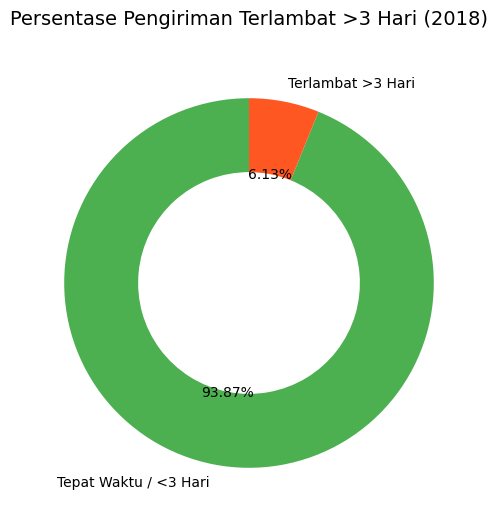

In [ ]:
plt.figure(figsize=(6, 6))
labels = ['Tepat Waktu / <3 Hari', 'Terlambat >3 Hari']
sizes = [total_orders - delayed_3d_orders, delayed_3d_orders]
colors = ['#4CAF50', '#FF5722']

plt.pie(sizes, labels=labels, autopct='%1.2f%%', startangle=90, colors=colors, wedgeprops={'width': 0.4})
plt.title('Persentase Pengiriman Terlambat >3 Hari (2018)', fontsize=14, pad=20)
plt.show()

### Pertanyaan 2:

Horizontal Bar Chart karena membandingkan tiap kategori dari yang terbesar

C:\Users\lenov\AppData\Local\Temp\ipykernel_13140\3787861224.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


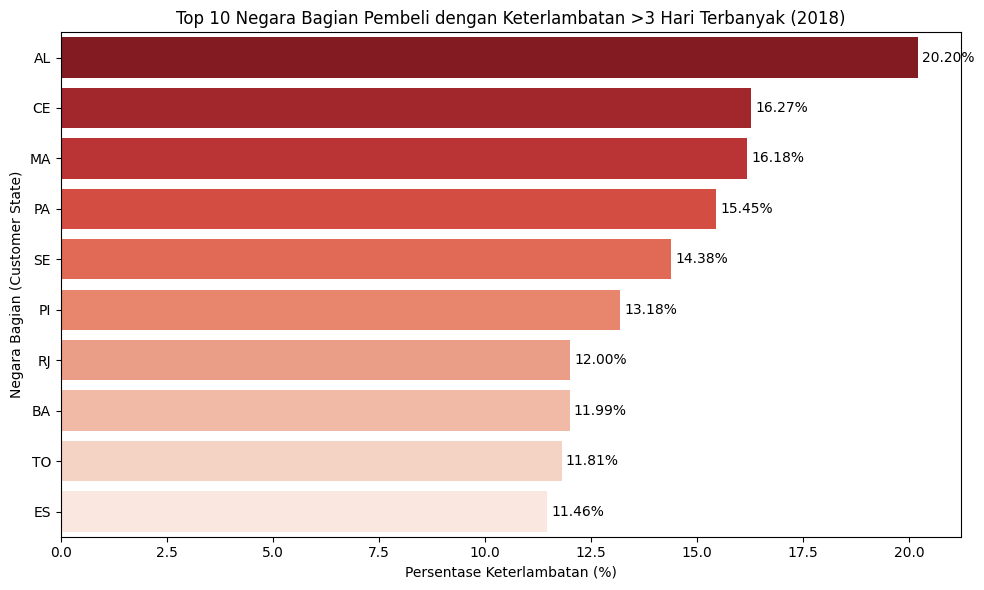

In [ ]:
plt.figure(figsize=(10, 6))
top_10_states = state_delay_df.head(10)

sns.barplot(
    data=top_10_states,
    x='persentase_terlambat',
    y='customer_state',
    hue='customer_state',
    palette='Reds_r',
    legend=False
)

plt.title('Top 10 Negara Bagian Pembeli dengan Keterlambatan >3 Hari Terbanyak (2018)', fontsize=12)
plt.xlabel('Persentase Keterlambatan (%)')
plt.ylabel('Negara Bagian (Customer State)')

# label angka di ujung bar
for index, row in top_10_states.iterrows():
    plt.text(row['persentase_terlambat'] + 0.1, index, f"{row['persentase_terlambat']:.2f}%", va='center')

plt.tight_layout()
plt.show()

## Analisis Lanjutan

Manual Clustering / Binning Risiko Keterlambatan State. Analisis ini digunakan karena mengelompokkan risiko menjadi kategori diskrit membuat tim dapat menentukan mana area yang memerlukan prioritas penanganan darurat terlebih dahulu. Estimasi pada area yang masuk pada risiko tinggi dapat secara otomatis disesuaikan oleh sistem.

In [ ]:
def categorize_delay_risk(percentage):
    if percentage >= 15.0:
        return 'High Risk'
    elif percentage >= 11.0:
        return 'Medium Risk'
    else:
        return 'Low Risk'

# Terapkan pengelompokan (Binning)
state_delay_df['risk_cluster'] = state_delay_df['persentase_terlambat'].apply(categorize_delay_risk)

print("Hasil Clustering Risiko Keterlambatan Negara Bagian:")
print(state_delay_df['risk_cluster'].value_counts())

Hasil Clustering Risiko Keterlambatan Negara Bagian:
risk_cluster
Low Risk       17
Medium Risk     6
High Risk       4
Name: count, dtype: int64


**Insight:**
- Terdapat 17 negara bagian dengan risiko keterlambatan rendah (< 11%), 6 negara bagian dengan risiko keterlambatan menengah (>= 11%), dan 4 negara bagian dengan risiko keterlambatan tinggi (>= 15%)

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Persentase pengiriman yang mengalami keterlambatan lebih dari 3 hari adalah **6.13%** (3236 dari 52777 pengiriman yang valid)
- **Conclusion pertanyaan 2:** Negara bagian yang mengalami keterlambatan pengiriman terbanyak adalah AL, CE, MA, dan PA yang masing-masingnya adalah 20.2%, 16.27%, 16.18%, dan 15.45%

**Rekomendasi Action Item:**
- Perlu dilakukan penyesuaian estimasi pengiriman otomatis untuk negara bagian yang sering terlambat agar meminimalkan reaksi negatif dari pelanggan
- Perlu melakukan pemeriksaan performa logistik pada mitra-mitra pengiriman pihak ketiga untuk area tujuan utama yang masih terlambat